## A3 · Lists, tuples and dictionaries

Python's built-in containers, including dictionaries, which are used constantly in pandas.

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Lists

#### Creating a list

**A3.01**

`l = [item_1, item_2, item_3]`

Square brackets allow us to store several values in order in one variable. It is useful for small collections of values. Alternatively, a NumPy array is better for maths, and a pandas Series for labelled data.

A list holds several values in order, written in square brackets. It can mix types.

In [111]:
heights = [165, 187, 164, 172]
names = ["Ana", "Bo", "Cy"]
mixed = [1, "two", 3.0, True]
heights

[165, 187, 164, 172]

In [112]:
type(heights)

list

*See also:* Picking an item from a list by position (A3) · Summarising a list with len, sum, max, min (A3) · Creating an array (A4)

#### Summarising a list with len, sum, max, min

**A3.02**

`len(l)  sum(l)  max(l)  min(l)`

The built-in functions `len`, `sum`, `max` and `min` allow us to summarise a list quickly. They are useful for a quick count, total, or range. Alternatively, convert to an array or Series and use `.mean()`, `.std()` and friends.

The mean of a list is `sum(l) / len(l)`.

In [113]:
heights = [165, 187, 164, 172]
print(f"count: {len(heights)}")
print(f"sum  : {sum(heights)}")
print(f"max  : {max(heights)}")
print(f"min  : {min(heights)}")
print(f"mean : {sum(heights) / len(heights):.1f}")

count: 4
sum  : 688
max  : 187
min  : 164
mean : 172.0


*See also:* Creating a list (A3) · Summarising an array (A4)

#### Adding an item to a list

**A3.03**

`l.append(x)`

The `.append()` method allows us to add one item to the end of a list. It is useful when building a list during a loop. Alternatively, `list1 + list2` joins two lists, and `.extend()` adds several items at once.

`append` adds one item to the end and changes the list itself (it returns nothing).

In [114]:
heights = [165, 187, 164]
heights                     # the list before

[165, 187, 164]

In [115]:
heights.append(180)

In [116]:
# display example data
heights                     # one item added at the end

[165, 187, 164, 180]

In [117]:
heights.append(150)

In [118]:
# display example data
heights

[165, 187, 164, 180, 150]

*See also:* Collecting results in a list with `append` (A2) · Removing an item from a list (A3)

#### Removing an item from a list

**A3.04**

`l.pop(), l.pop(i)`

The `.pop()` method allows us to remove an item and keep its value. It is useful for taking items off a list one at a time. Alternatively, `.remove(x)` deletes by value and `del l[i]` deletes by position.

`pop()` removes and **returns** the last item; `pop(0)` removes the first.

In [119]:
heights = [165, 187, 164, 172]
heights                   # the list before

[165, 187, 164, 172]

In [120]:
last = heights.pop()      # removes and returns 172
last

172

In [121]:
first = heights.pop(0)    # removes and returns 165
first

165

In [122]:
# display example data
heights                   # the list after both removals

[187, 164]

*See also:* Searching and editing a list (A3) · Adding an item to a list (A3) · Picking an item from a list by position (A3)

#### Joining two lists

**A3.05**

`l1 + l2`

The `+` operator allows us to join two lists into a new longer one. It is useful for combining results. Alternatively, `.extend()` adds to an existing list in place, and `pd.concat` joins DataFrames.

`+` makes a new, longer list. The originals are unchanged.

In [123]:
a = [1, 2]
b = [3, 4]
c = a + b
c

[1, 2, 3, 4]

In [124]:
print(a, b)               # the originals are unchanged

[1, 2] [3, 4]


*See also:* Stacking rows (B6) · Adding an item to a list (A3) · Creating a list (A3) · Joining text columns (B7)

#### Picking an item from a list by position

**A3.06**

`l[0], l[-1]`

Square brackets with a number allow us to pick out a single item by its position. It is useful for the first or last value in a list. Alternatively, `.iloc[]` does the same job for a pandas column.

Positions start at 0. Negative numbers count back from the end.

In [125]:
l = [10, 20, 30, 40, 50]
print(l[0])    # first
print(l[2])    # third
print(l[-1])   # last
print(l[-2])   # second from last

10
30
50
40


*See also:* Slicing a list (A3) · IndexError: index out of range (A1) · Indexing and slicing an array (A4)

#### Slicing a list

**A3.07**

`l[1:4], l[:3], l[2:], l[:]`

A slice `l[a:b]` allows us to take a section of a list. It is useful for the first few values or everything after a point. Alternatively, `.iloc[a:b]` slices rows of a DataFrame in the same way.

`l[a:b]` takes positions a up to but **not including** b. Omitting a number runs to the start or the end.

In [126]:
l = [10, 20, 30, 40, 50]
print(l[1:4])   # positions 1, 2, 3
print(l[:3])    # first three
print(l[2:])    # from position 2 to the end
print(l[:])     # everything (a copy)

[20, 30, 40]
[10, 20, 30]
[30, 40, 50]
[10, 20, 30, 40, 50]


*See also:* Selecting one row by position (B3) · Picking an item from a list by position (A3) · Slicing with a step and reversing a list (A3) · Views and copies of an array slice (A4)

#### Slicing with a step and reversing a list

**A3.08**

`l[0:6:2], l[::-1]`

Adding a step to a slice allows us to take every n-th item, or reverse the order with `-1`. It is useful for sampling regularly or flipping a list. Alternatively, `reversed(l)` and `sorted(l, reverse=True)` do similar things.

A third number is the step. A step of −1 reverses.

In [127]:
l = [10, 20, 30, 40, 50, 60]
l[0:6:2]    # every second item

[10, 30, 50]

In [128]:
l[::-1]     # reversed

[60, 50, 40, 30, 20, 10]

*See also:* Slicing a list (A3) · Creating a list (A3)

#### Changing an item in a list

**A3.09**

`l[i] = value`

Assigning to a position allows us to replace an item in a list. This is useful for correcting a value. Alternatively, a tuple cannot be changed, which is safer when values must stay fixed.

Assigning to a position replaces that item (lists are "mutable"). Tuples and strings cannot be changed this way.

In [129]:
l = [1, 2, 3]
l                          # before

[1, 2, 3]

In [130]:
l[0] = 999
l                          # after changing the first item

[999, 2, 3]

In [131]:
l[-1] = "last"
l                          # after changing the last item

[999, 2, 'last']

*See also:* Picking an item from a list by position (A3) · Copies and aliases of a list (A3) · Changing values in a column (B4)

#### Copies and aliases of a list

**A3.10**

`b = a   vs   b = a.copy()`

The `.copy()` method allows us to make an independent copy of a list, whereas `b = a` only gives the same list a second name. It is useful whenever one list must be changed without affecting the other. Alternatively, `a[:]` also makes a copy.

`b = a` does **not** make a copy: both names point at the same list, so changing one changes the other.

In [132]:
a = [1, 2, 3]
b = a            # alias: same list
c = a.copy()     # a real, separate copy
a[0] = 999
print(f"a: {a}")
print(f"b: {b}")   # changed too
print(f"c: {c}")   # unchanged

a: [999, 2, 3]
b: [999, 2, 3]
c: [1, 2, 3]


*See also:* Changing an item in a list (A3) · Views and copies of an array slice (A4) · Copying a filtered table (B3) · Sorting a list (A3)

#### Sorting a list

**A3.11**

`sorted(l), l.sort()`

***(non-examinable)***

The `sorted()` function and `.sort()` method allow us to put a list in order. They are useful for ranking values. Alternatively, in pandas use `sort_values()`.

`sorted(l)` returns a new list; `l.sort()` sorts the list in place.

In [133]:
l = [3, 1, 2]
sorted(l)                  # a new, sorted list

[1, 2, 3]

In [134]:
sorted(l, reverse=True)

[3, 2, 1]

In [135]:
# display example data
l                          # the original is unchanged

[3, 1, 2]

In [136]:
l.sort()                   # sorts in place (returns nothing)

In [137]:
# display example data
l                          # now sorted

[1, 2, 3]

*See also:* Creating a list (A3) · Searching and editing a list (A3)

#### Searching and editing a list

**A3.12**

`l.count(x), l.index(x), l.remove(x), l.insert(i, x)`

***(non-examinable)***

Methods such as `.count()`, `.index()`, `.remove()` and `.insert()` allow us to search and edit a list. They are useful for small data-cleaning jobs. Alternatively, pandas methods do similar things for whole columns.

Four methods for searching and editing a list. `remove` deletes by value (the first match); `insert` places an item at a chosen position.

In [138]:
l = [5, 3, 5, 1]
l.count(5)            # how many 5s

2

In [139]:
l.index(3)            # position of the first 3

1

In [140]:
l.remove(5)           # removes the first 5

In [141]:
l.insert(0, 99)       # inserts 99 at position 0

In [142]:
# display example data
l

[99, 3, 5, 1]

*See also:* Adding an item to a list (A3) · Removing an item from a list (A3) · Building a list with a list comprehension (A3) · Looping over a list (A2)

#### Building a list with a list comprehension

**A3.13**

`[x * 2 for x in l]`

***(non-examinable)***

A list comprehension allows us to build a new list from an old one in a single line. It is useful for transforming or filtering values. Alternatively, a `for` loop with `.append()` builds the same list and suits steps that need several lines.

A compact way to build a list from another list.

In [143]:
[x * 2 for x in [1, 2, 3]]

[2, 4, 6]

In [144]:
[x for x in range(10) if x % 2 == 0]   # with a condition

[0, 2, 4, 6, 8]

*See also:* Adding an item to a list (A3) · Looping over a list (A2)

### Tuples

#### Unpacking a tuple

**A3.14**

`rows, cols = df.shape`

Unpacking allows us to split a tuple into separate named variables in one line. It is useful for `df.shape`, which returns (rows, columns). Alternatively, index the tuple with `shape[0]` and `shape[1]`.

A tuple is like a list that cannot be changed, written with round brackets. It can be **unpacked** into several variables at once.

In [145]:
point = (3, 4)
point                      # a tuple

(3, 4)

In [146]:
x, y = point               # unpack into two variables
print(f"x = {x}, y = {y}")

x = 3, y = 4


`df.shape` is a tuple:

In [147]:
rows, cols = df_penguins.shape
print(f"{rows} rows and {cols} columns")

344 rows and 7 columns


*See also:* Checking the size of a DataFrame (B1) · Unpacking the output of `linregress` (A3) · Looping over two lists with `zip` (A2)

#### Unpacking the output of `linregress`

**A3.15**

`slope, intercept, r, p, se = linregress(x, y)`

If a function returns several values as a tuple, then unpacking gives each one a name. It is useful for `linregress`, which returns five results. Alternatively, store the result and read named attributes, like `result.slope`.

Many functions return several values as a tuple. These can be unpacked into named variables.

In [148]:
x = [1, 2, 3, 4, 5]
y = [2.1, 3.9, 6.2, 7.8, 10.1]
slope, intercept, r, p, se = stats.linregress(x, y)
print(f"slope     = {slope:.2f}")

slope     = 1.99


In [149]:
print(f"intercept = {intercept:.2f}")

intercept = 0.05


*See also:* Unpacking a tuple (A3) · Fitting a line (D5) · Creating a variable (A1)

### Dictionaries

#### Creating a dictionary

**A3.16**

`d = {key_1: value_1, key_2: value_2}`

A dictionary allows us to store values under meaningful names (keys) rather than positions. It is useful for records with named fields, or for lookups. Alternatively, a pandas Series with labels behaves very similarly.

A dictionary stores **key: value** pairs inside curly brackets. Keys are usually text; values can be anything.

In [150]:
d = {"name": "Alice", "age": 21}
print(d)
print(type(d))
print(f"{len(d)} entries")

{'name': 'Alice', 'age': 21}
<class 'dict'>
2 entries


*See also:* Looking up a value in a dictionary (A3) · Creating a DataFrame from a dictionary (B1) · Adding or changing a dictionary entry (A3)

#### Looking up a value in a dictionary

**A3.17**

`d['age']`

Square brackets with a key allow us to fetch the matching value from a dictionary. It is useful when the name of the required item is known. Alternatively, `.get(key, default)` avoids an error if the key is missing.

Use the key where a position would be used in a list.

In [151]:
d = {"name": "Alice", "age": 21}
d['age']

21

In [152]:
d['name']

'Alice'

*See also:* Creating a dictionary (A3) · Adding or changing a dictionary entry (A3) · KeyError: key not found (A1)

#### Adding or changing a dictionary entry

**A3.18**

`d['dept'] = 'Bio'`

Assigning to a key allows us to add a new entry or overwrite an existing one. It is useful for building a dictionary up step by step. Alternatively, `.update(other_dict)` merges in several entries at once.

Assigning to a new key adds it; assigning to an existing key overwrites it.

In [153]:
d = {"name": "Alice", "age": 21}
d                    # the dictionary before

{'name': 'Alice', 'age': 21}

In [154]:
d["dept"] = "Bio"    # new key
d                    # one entry added

{'name': 'Alice', 'age': 21, 'dept': 'Bio'}

In [155]:
d["age"] = 22        # existing key
d                    # the value is overwritten

{'name': 'Alice', 'age': 22, 'dept': 'Bio'}

*See also:* Looking up a value in a dictionary (A3) · Changing an item in a list (A3) · Testing whether a key exists (A3)

#### Listing keys, values and items

**A3.19**

`d.keys(), d.values(), d.items()`

The methods `.keys()`, `.values()` and `.items()` allow us to see what a dictionary contains. They are useful for checking or looping over its contents. Alternatively, `list(d)` gives only the keys.

In [156]:
d = {"name": "Alice", "age": 21, "dept": "Bio"}
print(list(d.keys()))
print(list(d.values()))
print(list(d.items()))   # pairs of (key, value)

['name', 'age', 'dept']
['Alice', 21, 'Bio']
[('name', 'Alice'), ('age', 21), ('dept', 'Bio')]


*See also:* Looping over a dictionary (A3) · Testing whether a key exists (A3) · Looking up a value in a dictionary (A3)

#### Testing whether a key exists

**A3.20**

`'age' in d`

The `in` operator allows us to check whether a key exists before using it. It is useful for avoiding a `KeyError`. Alternatively, `.get(key)` returns `None` when the key is missing.

`in` checks the **keys**.

In [157]:
d = {"name": "Alice", "age": 21}
'age' in d

True

In [158]:
print("height" in d)
if "height" not in d:
    print("no height recorded")

False
no height recorded


*See also:* Testing membership with `in` (A2) · Looking up a value in a dictionary (A3)

#### Looping over a dictionary

**A3.21**

`for k, v in d.items():`

The `.items()` method allows us to loop over keys and values together. It is useful for printing or processing every entry. Alternatively, loop over `d` (keys only) and look up each value.

Each item comes as a (key, value) pair that is unpacked into two variables.

In [159]:
d = {"name": "Alice", "age": 21, "dept": "Bio"}
for k, v in d.items():
    print(f"{k} -> {v}")

name -> Alice
age -> 21
dept -> Bio


*See also:* Listing keys, values and items (A3) · Unpacking a tuple (A3) · Looking up with a default value using `get` (A3)

#### Looking up with a default value using `get`

**A3.22**

`d.get(key, default)`

***(non-examinable)***

The `.get()` method allows us to look up a key but give a fallback when it is missing. It is useful when some records lack a field. Alternatively, test `key in d` first with an `if`.

`d['x']` raises a `KeyError` if the key is missing; `.get` returns a default instead.

In [160]:
d = {"name": "Alice", "age": 21}
d.get('age', 'unknown')

21

In [161]:
d.get('height', 'unknown')

'unknown'

*See also:* KeyError: key not found (A1) · Looking up a value in a dictionary (A3)

### Dictionaries in pandas

#### Turning a dictionary into a DataFrame

**A3.23**

`pd.DataFrame({'col': values})`

If we have our data as a dictionary of lists, then passing it to `pd.DataFrame` makes a table with one column per key. It is useful for small tables typed straight into the notebook. Alternatively, `pd.read_csv` loads a table from a file.

Each key becomes a column name and each list becomes that column's values.

In [162]:
data = {"name": ["Ana", "Bo"], "age": [21, 25]}
data                         # a dictionary of lists

{'name': ['Ana', 'Bo'], 'age': [21, 25]}

In [163]:
df = pd.DataFrame(data)
df                           # the same data as a table

,name,age
0,Ana,21
1,Bo,25


*See also:* Reading a CSV file (B1) · Creating a dictionary (A3) · Creating a DataFrame from a dictionary (B1)

#### Renaming pandas columns with a dictionary

**A3.24**

`df.rename(columns={'old': 'new'})`

If we want to change only some column names, then a dictionary of old name → new name passed to `rename(columns=...)` does it. It is useful for fixing a few awkward names. Alternatively, assign a full list to `df.columns`.

The dictionary maps old names to new names. Columns not mentioned are left alone.

In [164]:
df = pd.DataFrame({"name": ["Ana", "Bo"], "age": [21, 25]})

In [165]:
# display example dataframe
df

,name,age
0,Ana,21
1,Bo,25


In [166]:
mapping = {"age": "age_years"}
df.rename(columns=mapping)

,name,age_years
0,Ana,21
1,Bo,25


*See also:* Renaming columns with a dictionary (B2) · Turning a dictionary into a DataFrame (A3)

#### Recoding values with a dictionary

**A3.25**

`s.replace({old: new}), s.map(d)`

If a column holds codes like `'A'` and `'G'`, then a dictionary passed to `.replace()` recodes them into readable labels. It is useful for tidying category labels. Alternatively, `.map()` does the same but turns unmatched values into `NaN`.

Adelie, Chinstrap and Gentoo are the three penguin species in this dataset.

In [167]:
col_species = pd.Series(["A", "G", "G", "A"])

In [168]:
# display example series
col_species

0    A
1    G
2    G
3    A
dtype: object

In [169]:
col_species.replace({'A': 'Adelie', 'G': 'Gentoo'}).tolist()

['Adelie', 'Gentoo', 'Gentoo', 'Adelie']

*See also:* Replacing and mapping values (B4) · Turning a dictionary into a DataFrame (A3)

#### Passing plot options as a dictionary

**A3.26**

`line_kws={'color': 'red'}`

If a plotting argument such as `line_kws` takes several options, then a dictionary allows us to pass them together. It is useful for styling the fitted line in `regplot`. Alternatively, plot the points and line separately with matplotlib.

Some plotting arguments take a dictionary of options that is passed on to the line being drawn.

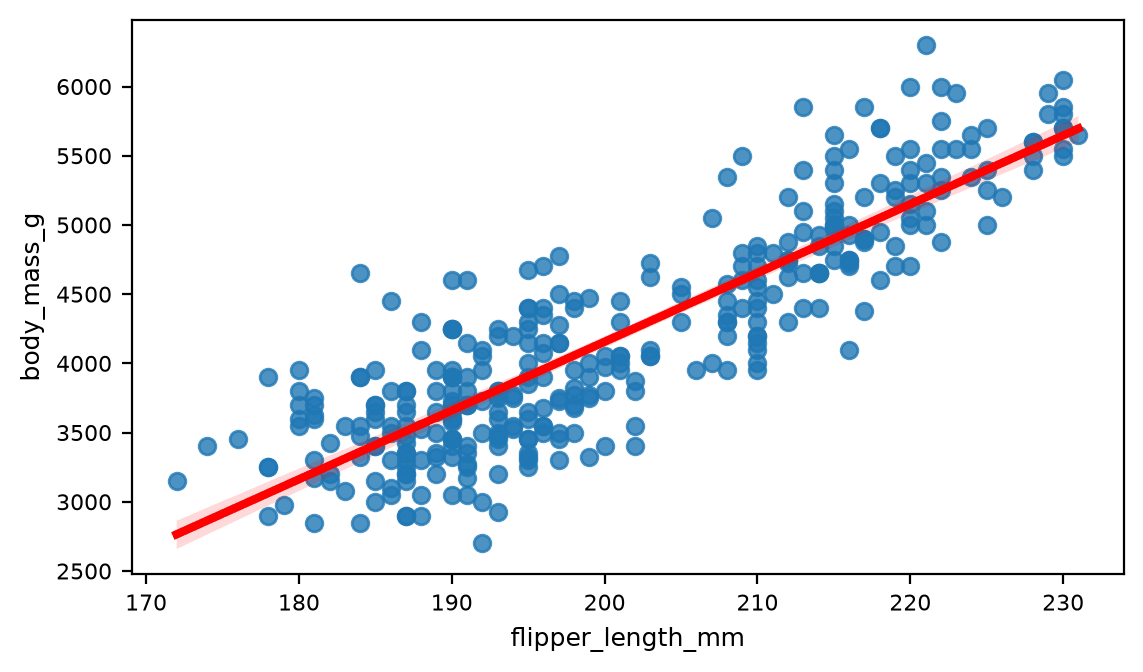

In [170]:
sns.regplot(data=df_penguins, x="flipper_length_mm", y="body_mass_g",
            line_kws={"color": "red", "linewidth": 3});

*See also:* Drawing a scatter with a fitted line (C3) · Turning a dictionary into a DataFrame (A3) · Creating a dictionary (A3)